# Plot cutflows

In [2]:
import warnings
warnings.filterwarnings("ignore", message="numpy.dtype size changed")
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
pd.option_context('display.max_columns', -1)

# plt.style.use('fivethirtyeight') #Set style
# mpl.rcParams.update({'figure.figsize' : (15,10)})  #Set general plotting options
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica"]})

plt.rcParams.update({"savefig.dpi" : 300}) #Figure resolution


#Define plotting style:
sns.set_style('ticks',{'font.family':'Times New Roman', 'font.serif':'Times New Roman'})
sns.set_context('paper', font_scale=1.3)
cm = plt.colormaps['RdYlBu']

In [3]:
def closestRow(df, point, relative=True):
    """Return a one-row DataFrame with the row of df closest to point 
    (dict column -> value)."""
    cols = list(point.keys())
    target = pd.Series(point)
    diff = df[cols] - target
    if relative:
        diff = diff / target.abs().where(target != 0, 1.0)   # relative difference (absolute if target is 0)
    dist = (diff**2).sum(axis=1)
    return df.loc[[dist.idxmin()]]   # double brackets keep it a DataFrame


## Load CutFlows

In [4]:
b2tfCutFlows_DF = pd.read_csv('../b2tf_cutFlow_13TeV_y21_3.csv')
b2tfCutFlows_DF['dm'] = (b2tfCutFlows_DF['m1']-b2tfCutFlows_DF['m0']).round(0)
b2tfCutFlows_DF['ctau'] = (b2tfCutFlows_DF['tau']*2.99e8).round(0)
b2tfCutFlows_DF['eff'] = b2tfCutFlows_DF['(n+1): nroi >= 3']/b2tfCutFlows_DF['all']
# Remove large deltaM, which results in promptly decaying chi1 through the process chi1 -> chi2* + h -> (chi0 + h) + h
b2tfCutFlows_DF = b2tfCutFlows_DF[b2tfCutFlows_DF['dm'] < 250.0].copy()


### Plot cutflow

In [5]:
cf_labels = {
    'all': 'Total',
    'l1(n): 200 gev < met(n)': r'L1: $E_T^{\rm miss} > 200$ GeV',
    'l1(n): 150 gev < ptj1(n)': r'L1: $p_T^{j_1} > 150$ GeV',
    '(n+1): 25 ns < t < 50 ns': r'25 ns $ < t < 50$ ns',
    '(n+1): decay in ms': 'Decay in MS',
    '(n+1): nroi >= 3': r'$n_{\rm RoI} \geq 3$',
}


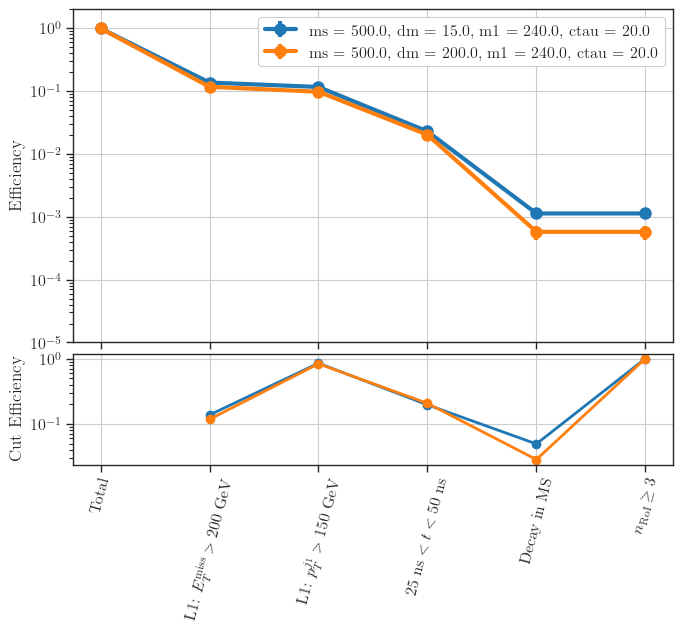

In [6]:
fig, (ax, axr) = plt.subplots(2, 1, figsize=(7,6.5), sharex=True,
                              gridspec_kw={'height_ratios': [3, 1]})

selectPoints = [{'ms' : 500.0, 'dm' : 15.0, 'm1' : 240.0, 'ctau' : 20.0},  {'ms' : 500.0, 'dm' : 200.0, 'm1' : 240.0, 'ctau' : 20.0}]

x_ticks = list(cf_labels.keys())
x_ticksL = [cf_labels.get(c, c) for c in x_ticks]
x = np.arange(0.,len(x_ticksL),1.)
for pt in selectPoints:
    data = closestRow(b2tfCutFlows_DF, pt)
    label = ', '.join([f'{key} = {data[key].iloc[0]}' for key in pt])
    y = (data.iloc[0][x_ticks]/data.iloc[0]['all']).values.astype(float)
    yerr = y/np.sqrt(data.iloc[0][x_ticks].values.astype(float))
    p = ax.errorbar(x,y,label=label,linewidth=3,marker='o',markersize=8,yerr=yerr)
    # Ratio bin(i)/bin(i-1) (relative efficiency of each cut)
    with np.errstate(divide='ignore', invalid='ignore'):
        ratio = y[1:]/y[:-1]
    axr.plot(x[1:],ratio,linewidth=2,marker='o',markersize=6,color=p[0].get_color())
ax.set_yscale('log')
ax.set_ylabel('Efficiency')
ax.set_ylim(1e-5,2.0)
ax.legend(framealpha=1.0)
ax.grid()

axr.set_yscale('log')
axr.set_ylabel(r'Cut Efficiency')
axr.grid()
axr.set_xticks(x)
axr.set_xticklabels(x_ticksL,rotation=75)
fig.align_ylabels([ax, axr])
plt.tight_layout()
plt.subplots_adjust(hspace=0.05)
plt.show()

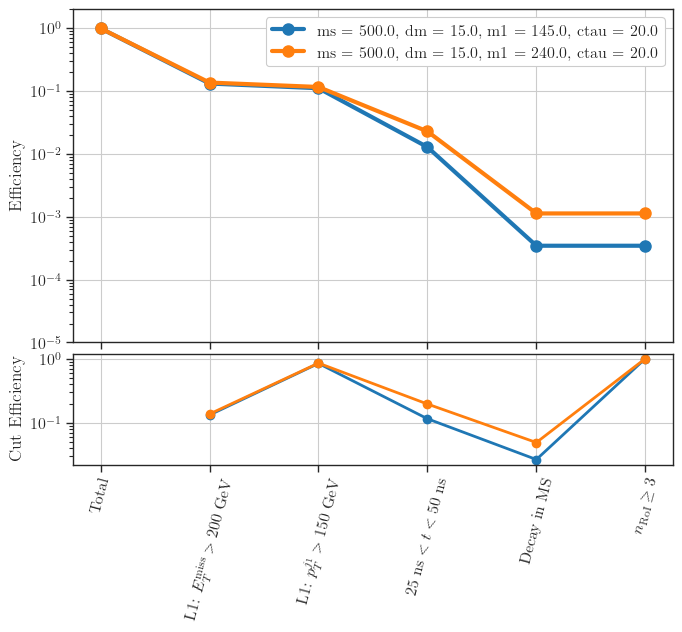

In [8]:
fig, (ax, axr) = plt.subplots(2, 1, figsize=(7,6.5), sharex=True,
                              gridspec_kw={'height_ratios': [3, 1]})

selectPoints = [{'ms' : 500.0, 'dm' : 15.0, 'm1' : 150.0, 'ctau' : 20.0},  {'ms' : 500.0, 'dm' : 15.0, 'm1' : 240.0, 'ctau' : 20.0}]

x_ticks = list(cf_labels.keys())
x_ticksL = [cf_labels.get(c, c) for c in x_ticks]
x = np.arange(0.,len(x_ticksL),1.)
for pt in selectPoints:
    data = closestRow(b2tfCutFlows_DF, pt)
    label = ', '.join([f'{key} = {data[key].iloc[0]}' for key in pt])
    y = (data.iloc[0][x_ticks]/data.iloc[0]['all']).values.astype(float)
    p = ax.plot(x,y,label=label,linewidth=3,marker='o',markersize=8)
    # Ratio bin(i)/bin(i-1) (relative efficiency of each cut)
    with np.errstate(divide='ignore', invalid='ignore'):
        ratio = y[1:]/y[:-1]
    axr.plot(x[1:],ratio,linewidth=2,marker='o',markersize=6,color=p[0].get_color())
ax.set_yscale('log')
ax.set_ylabel('Efficiency')
ax.set_ylim(1e-5,2.0)
ax.legend(framealpha=1.0)
ax.grid()

axr.set_yscale('log')
axr.set_ylabel(r'Cut Efficiency')
axr.grid()
axr.set_xticks(x)
axr.set_xticklabels(x_ticksL,rotation=75)
fig.align_ylabels([ax, axr])
plt.tight_layout()
plt.subplots_adjust(hspace=0.05)
plt.show()